<a href="https://colab.research.google.com/github/Ysabellyysa/Python/blob/main/Variational_Auto_Encoders_Pratica_Nova_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import random
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import cifar10
from matplotlib import pyplot as plt

print("GPUs disponíveis: ", len(tf.config.list_physical_devices('GPU')))

GPUs disponíveis:  1


In [2]:
SEED = 123456
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [3]:
(x_train, y_train), (x_test, y_test) = cifar10.load_data()
y_train, y_test = y_train.flatten(), y_test.flatten() # rótulos como números simples

categorias = {
    0: "Avião", 1: "Automóvel", 2: "Pássaro", 3: "Gato", 4: "Cervo",
    5: "Cachorro", 6: "Sapo", 7: "Cavalo", 8: "Navio", 9: "Caminhão"
}

print(x_train.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2125s 12us/step
(50000, 32, 32, 3)


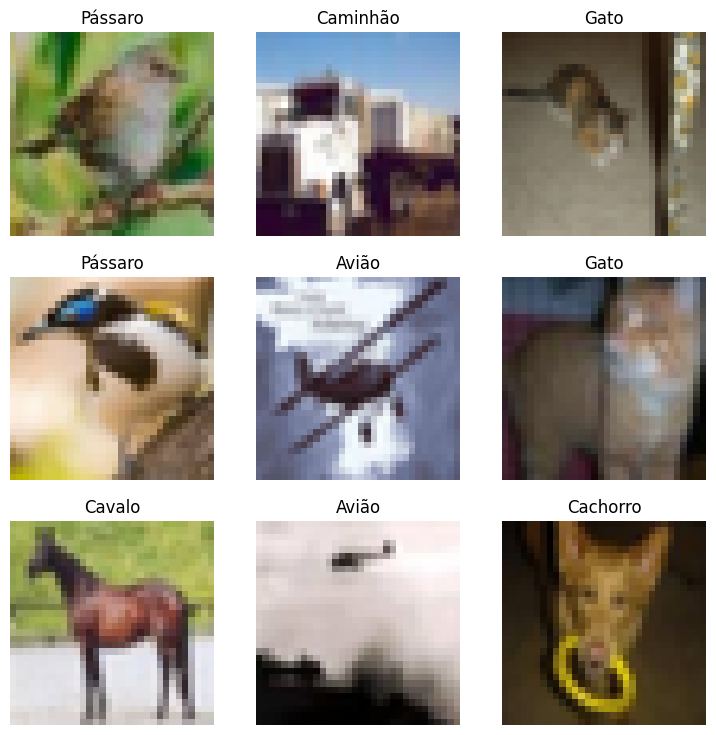

In [4]:
plt.figure(figsize=(9, 9))
rndSamples = np.random.choice(50000, 9)

for i in range(9):
    plt.subplot(3, 3, i+1)
    plt.imshow(x_train[rndSamples[i]])
    plt.title(categorias[int(y_train[rndSamples[i]])])
    plt.axis("off")
plt.show()

In [5]:
dataset = np.concatenate([x_train, x_test], axis=0)
dataset = dataset.astype("float32") / 255 # normaliza

# rótulos
labels = np.concatenate([y_train, y_test], axis=0).flatten()

In [6]:
class SamplingLayer(layers.Layer):
    # z = mu + sigma * epsilon

    def call(self, inputs):
        zMean, zLogVar = inputs
        batch = tf.shape(zMean)[0]
        dim = tf.shape(zMean)[1]
        epsilon = tf.random.normal(shape=(batch, dim)) # ruído normal
        return zMean + tf.exp(0.5 * zLogVar) * epsilon # reparametrização

In [7]:
LATENT_DIM = 16 # tamanho do espaço latente

def buildEncoder(latentDim, encoderInputs):
    # convoluções vão reduzindo a imagem (32 -> 16 -> 8 -> 4)
    l1 = keras.models.Sequential([
        layers.Conv2D(128, 3, activation="relu", strides=2, padding="same"),
        layers.Conv2D(64, 3, activation="relu", strides=2, padding="same"),
        layers.Conv2D(32, 3, activation="relu", strides=2, padding="same"),
        layers.Flatten(),
        layers.Dense(256, activation="relu")
    ])

    x = l1(encoderInputs)
    zMean = layers.Dense(latentDim, name="z_mean")(x) # média
    zLogVar = layers.Dense(latentDim, name="z_log_var")(x) # log da variância
    z = SamplingLayer()([zMean, zLogVar]) # sorteia o ponto latente

    return keras.Model(encoderInputs, [zMean, zLogVar, z], name="encoder")

encoderInputs = keras.Input(shape=(32, 32, 3))
encoder = buildEncoder(LATENT_DIM, encoderInputs)
encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 256)       │    227,168 │ input_layer[0][0] │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 16)        │      4,112 │ sequential[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 16)        │      4,112 │ sequential[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling_layer      │ (None, 16)        │          0 │ z_mean[0][0],     │
│ (SamplingLayer)     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 235,392 (919.50 KB)

 Trainable params: 235,392 (919.50 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
def buildDecoder(latentInputs):
    # faz o caminho inverso do encoder (4 -> 8 -> 16 -> 32)
    l1 = keras.models.Sequential([
        layers.Dense(4*4*64, activation="relu"),
        layers.Reshape((4, 4, 64)),
        layers.Conv2DTranspose(128, 3, activation="relu", strides=2, padding="same"),
        layers.Conv2DTranspose(64, 3, activation="relu", strides=2, padding="same"),
        layers.Conv2DTranspose(32, 3, activation="relu", strides=2, padding="same"),
        layers.Conv2DTranspose(3, 3, activation="sigmoid", padding="same") # 3 canais (rgb)
    ])

    return keras.Model(latentInputs, l1(latentInputs), name="decoder")

latentInputs = keras.Input(shape=(LATENT_DIM,))
decoder = buildDecoder(latentInputs)
decoder.summary()

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 32, 32, 3)      │       184,387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 184,387 (720.26 KB)

 Trainable params: 184,387 (720.26 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
def reconstructionLoss(data, reconstructed):
    # compara a imagem original com a reconstruída
    return tf.reduce_mean(
        tf.reduce_sum(
            keras.losses.binary_crossentropy(data, reconstructed),
            axis=(1, 2)
        )
    )

def klDivergenceLoss(zMean, zLogVar):
    # força a distribuição a ficar perto de uma normal
    return tf.reduce_mean(
        tf.reduce_sum(
            -0.5 * (1 + zLogVar - tf.square(zMean) - tf.exp(zLogVar)),
            axis=1
        )
    )

def calcTotalLoss(data, reconstructed, zMean, zLogVar):
    loss1 = reconstructionLoss(data, reconstructed)
    loss2 = klDivergenceLoss(zMean, zLogVar)
    klWeight = 3.0 # peso da kl
    return loss1, loss2, loss1 + klWeight * loss2

In [10]:
class VAE(keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.totalLossTracker = keras.metrics.Mean(name="total_loss")
        self.ceLossTracker = keras.metrics.Mean(name="ce_loss")
        self.klLossTracker = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [self.totalLossTracker, self.ceLossTracker, self.klLossTracker]

    def train_step(self, data):
        with tf.GradientTape() as tape:
            # encoder -> z -> decoder
            zMean, zLogVar, z = self.encoder(data)
            reconstruction = self.decoder(z)
            ceLoss, klLoss, totalLoss = calcTotalLoss(data, reconstruction, zMean, zLogVar)

        # calcula os gradientes e atualiza os pesos
        grads = tape.gradient(totalLoss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))

        self.totalLossTracker.update_state(totalLoss)
        self.ceLossTracker.update_state(ceLoss)
        self.klLossTracker.update_state(klLoss)

        return {
            "perda_total": self.totalLossTracker.result(),
            "perda_reconstrucao": self.ceLossTracker.result(),
            "perda_kl": self.klLossTracker.result()
        }

In [11]:
vae = VAE(encoder, decoder)
vae.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001))
history = vae.fit(dataset, epochs=32, batch_size=128)

Epoch 1/32
469/469 ━━━━━━━━━━━━━━━━━━━━ 24s 26ms/step - perda_kl: 3.8905 - perda_reconstrucao: 658.3164 - perda_total: 669.9880
Epoch 2/32
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - perda_kl: 5.6502 - perda_reconstrucao: 637.1904 - perda_total: 654.1407
Epoch 3/32
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - perda_kl: 6.0507 - perda_reconstrucao: 634.2198 - perda_total: 652.3721
Epoch 4/32
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - perda_kl: 6.4187 - perda_reconstrucao: 631.7861 - perda_total: 651.0419
Epoch 5/32
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - perda_kl: 6.7833 - perda_reconstrucao: 629.5350 - perda_total: 649.8849
Epoch 6/32
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - perda_kl: 6.8601 - perda_reconstrucao: 628.8058 - perda_total: 649.3860
Epoch 7/32
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - perda_kl: 6.9053 - perda_reconstrucao: 628.5284 - perda_total: 649.2441
Epoch 8/32
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - perda_kl: 6.9269 - perda_reconstrucao: 628.1943 - perda

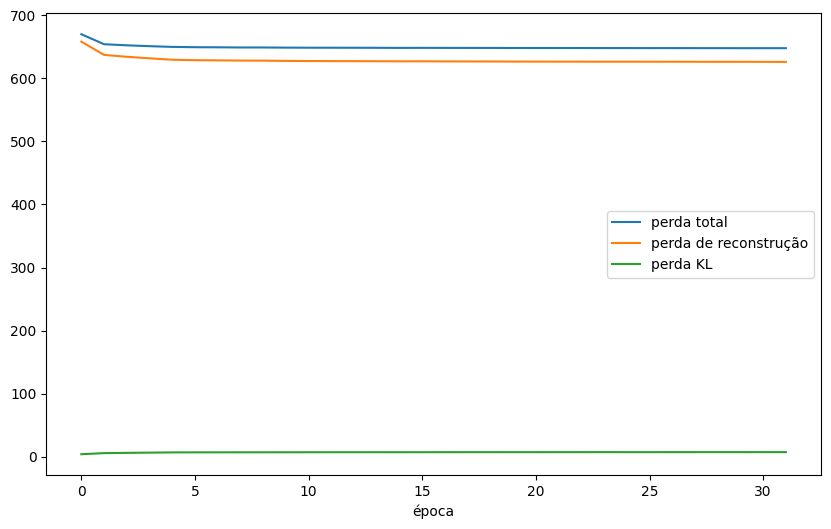

In [12]:
plt.figure(figsize=(10, 6))
plt.plot(history.history["perda_total"], label="perda total")
plt.plot(history.history["perda_reconstrucao"], label="perda de reconstrução")
plt.plot(history.history["perda_kl"], label="perda KL")
plt.xlabel("época")
plt.legend()
plt.show()

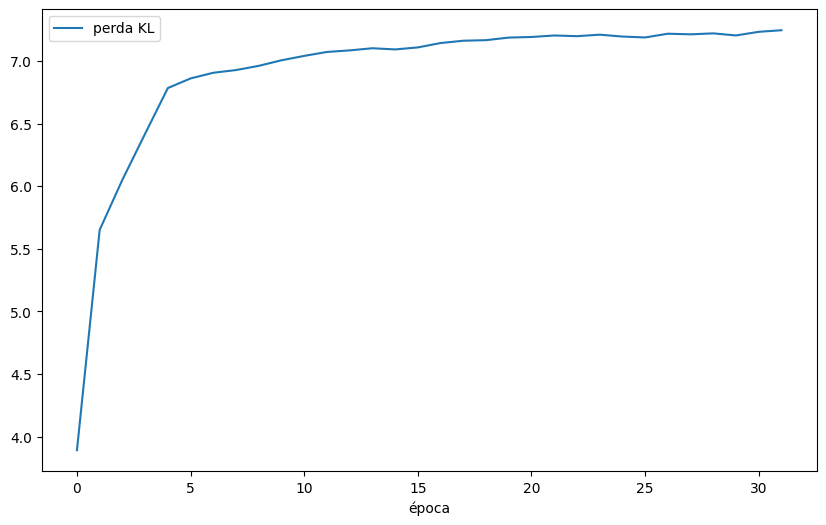

In [13]:
# zoom na perda kl
plt.figure(figsize=(10, 6))
plt.plot(history.history["perda_kl"], label="perda KL")
plt.xlabel("época")
plt.legend()
plt.show()

Categoria:  Pássaro
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 709ms/step


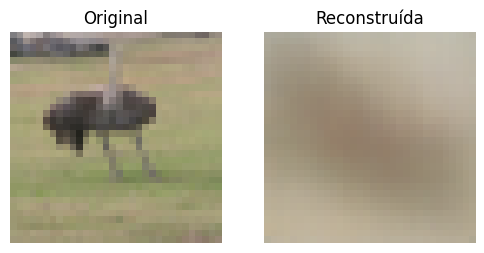

In [14]:
idx = 42
batch = np.expand_dims(x_train[idx], axis=0).astype("float32") / 255
print("Categoria: ", categorias[int(y_train[idx])])

_, _, z = vae.encoder.predict(batch) # codifica a imagem
synth = vae.decoder.predict(z) # reconstrói

plt.figure(figsize=(6, 3))
plt.subplot(1, 2, 1); plt.imshow(batch[0]); plt.title("Original"); plt.axis("off")
plt.subplot(1, 2, 2); plt.imshow(synth[0]); plt.title("Reconstruída"); plt.axis("off")
plt.show()

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 192ms/step


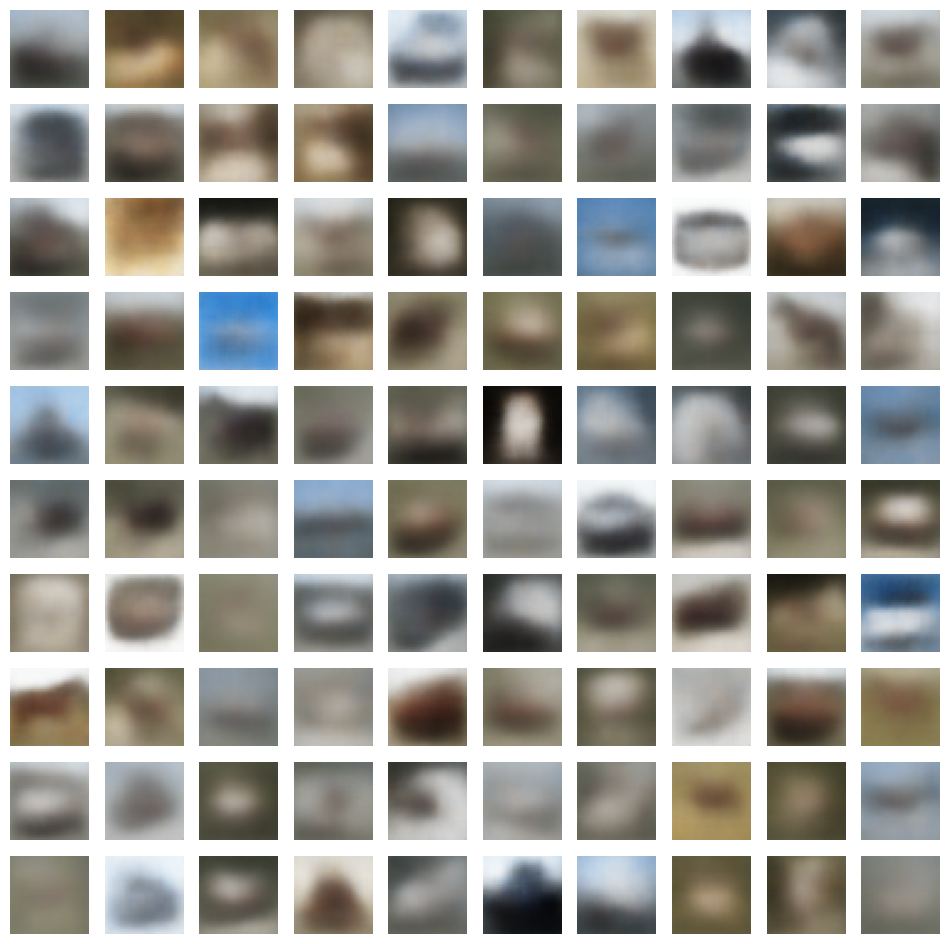

In [15]:
# sorteia pontos do espaço latente e gera imagens novas
z = np.random.normal(loc=0, scale=1, size=(100, LATENT_DIM))
synth = vae.decoder.predict(z)

plt.figure(figsize=(12, 12))
for i in range(100):
    plt.subplot(10, 10, i+1)
    plt.imshow(synth[i])
    plt.axis("off")
plt.show()

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step


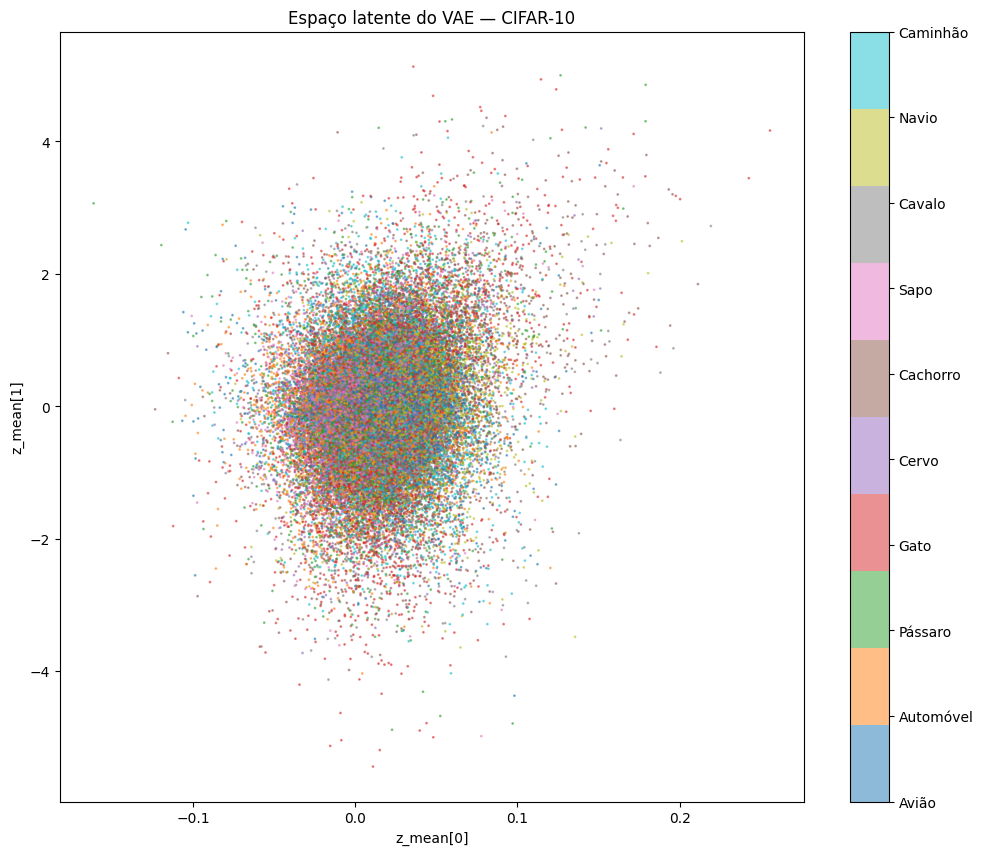

In [16]:
# usa a média de cada imagem como posição no espaço latente
zMeanAll, _, _ = vae.encoder.predict(dataset)

plt.figure(figsize=(12, 10))
scatter = plt.scatter(zMeanAll[:, 0], zMeanAll[:, 1], c=labels, cmap="tab10", alpha=0.5, s=1)
cbar = plt.colorbar(scatter, ticks=range(10))
cbar.ax.set_yticklabels([categorias[i] for i in range(10)])
plt.xlabel("z_mean[0]")
plt.ylabel("z_mean[1]")
plt.title("Espaço latente do VAE — CIFAR-10")
plt.show()